# Parliament (Semicircle) Chart

**Family:** Part-to-whole &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Part-to-whole:* Show how a single entity breaks down into its components.

## Design purpose

Seats drawn as dots arranged in semicircular rows and colored by party. Each dot is a countable unit, so the chart shows composition and whether a majority threshold is crossed.

## When to use

- Show seat allocation in a legislature or committee
- Show any whole made of discrete units where reaching a threshold (50%) matters

## Avoid when

- The units are not discrete or the counts are very large (thousands)
- There are many small parties (fold them into 'Other')

## Alternatives

- Waffle chart
- Single stacked bar with a majority line

## Example

Seats in a 120-seat parliament after a (fictional) election.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
seats = pd.Series({"Party A": 52, "Party B": 38, "Party C": 14, "Party D": 8, "Other": 8})
assert seats.sum() == 120
seats

Party A    52
Party B    38
Party C    14
Party D     8
Other       8
dtype: int64

### Plot

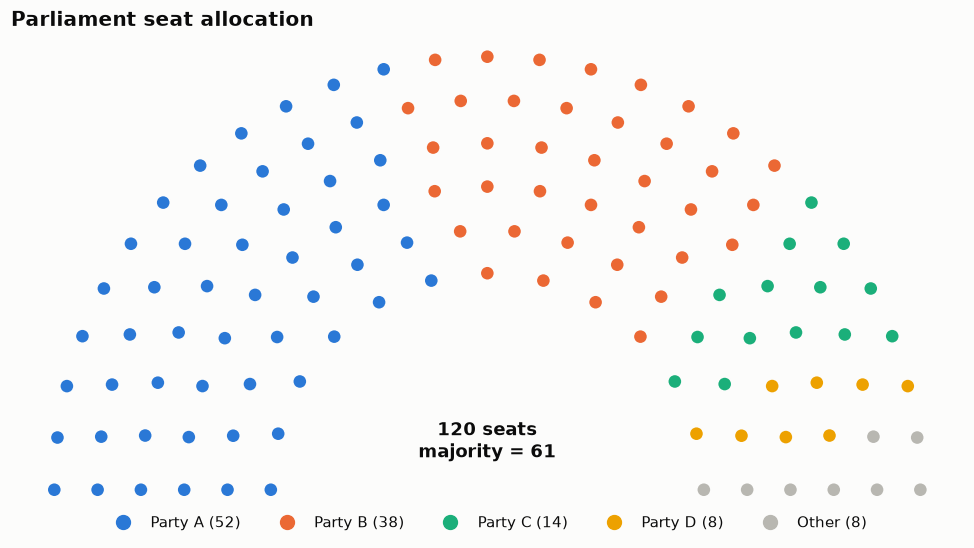

In [3]:
n_rows, total = 6, seats.sum()
radii = np.linspace(1.0, 2.0, n_rows)
per_row = np.round(radii / radii.sum() * total).astype(int)
per_row[-1] += total - per_row.sum()
pts = []
for r, n in zip(radii, per_row):
    for a in np.linspace(np.pi, 0, n):
        pts.append((a, r * np.cos(a), r * np.sin(a)))
pts.sort(key=lambda p: -p[0])           # fill left to right by angle
colors = PALETTE[:len(seats) - 1] + [GRAY]
seat_colors = np.repeat(colors, seats.values)
fig, ax = plt.subplots(figsize=(9, 5))
xs, ys = [p[1] for p in pts], [p[2] for p in pts]
ax.scatter(xs, ys, c=seat_colors, s=95, edgecolor="#fcfcfb", linewidth=1.5)
ax.text(0, 0.15, f"{total} seats\nmajority = {total // 2 + 1}", ha="center",
        fontsize=12, fontweight="bold")
ax.set_aspect("equal")
ax.axis("off")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, markersize=9) for c in colors]
ax.legend(handles, [f"{k} ({v})" for k, v in seats.items()], ncol=5,
          loc="upper center", bbox_to_anchor=(0.5, 0.02))
ax.set_title("Parliament seat allocation")
fig.tight_layout()
plt.show()

---
Standalone script: [`parliament_chart.py`](parliament_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)